# 04 – Models made for ordered scores (PoQeMoN QoE project)

**Problem found in notebook 03:** the regression models **never predict a 5** and turn most 3s into 4s.
They are pulled towards the average MOS (about 3.7), so they almost always say "4".
RMSE and MAE look fine, but macro F1 is only about 0.40.

**Goal of this notebook:** try 3 ideas that should fix this, and compare them with the **same nested cross-validation** as notebook 03 (same users in the same folds).

| Idea | What changes | Models |
|---|---|---|
| **A. Better rounding thresholds** | Keep the regression model, but learn **where to cut** between two scores instead of always cutting at 1.5, 2.5, 3.5, 4.5 | Ridge, random forest |
| **B. Classification with class weights** | Predict the score as a **class**, and give more weight to rare scores during training | Logistic regression, random forest classifier |
| **C. Ordinal regression** | A model made for **ordered** classes: one score + 4 learned cut points | Ordinal logistic regression (`mord`) |

Run `01_data_cleaning.ipynb` first: it creates `pokemon_clean.csv`.

In [1]:
# In Google Colab, the ordinal regression library must be installed first
try:
    import mord
except ImportError:
    %pip install -q mord
    import mord

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import BaseEstimator, RegressorMixin, clone
from sklearn.model_selection import GroupKFold, StratifiedGroupKFold, GridSearchCV, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import Ridge, LogisticRegression
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.metrics import (mean_squared_error, mean_absolute_error, cohen_kappa_score,
                             f1_score, accuracy_score, recall_score, confusion_matrix, make_scorer,
                             roc_auc_score)

warnings.filterwarnings("ignore", category=UserWarning)   # mord prints harmless solver messages

RANDOM_SEED = 42
N_OUTER = 5
N_INNER = 5
SCORES = [1, 2, 3, 4, 5]

## 1. Load the clean data and define the columns
Same columns as in notebooks 02 and 03 (without the QoF columns).

In [3]:
DATA_FILE = "pokemon_clean.csv"
if not os.path.exists(DATA_FILE):
    try:
        from google.colab import files   # only exists in Google Colab
        files.upload()                   # choose pokemon_clean.csv (made by notebook 1)
    except ImportError:
        raise FileNotFoundError("Run 01_data_cleaning.ipynb first: it creates pokemon_clean.csv")

df = pd.read_csv(DATA_FILE)

TARGET = "MOS"
GROUP = "user_id"
NUMERIC_FEATURES = [
    "QoA_VLCresolution", "QoA_VLCbitrate", "QoA_VLCframerate", "QoA_VLCdropped",
    "QoA_VLCaudiorate", "QoA_VLCaudioloss", "QoA_BUFFERINGcount", "log_BUFFERINGtime",
    "QoD_api-level", "QoU_sex", "QoU_age", "QoU_Ustedy",
]
CATEGORICAL_FEATURES = ["QoS_type", "QoS_operator", "QoD_model"]
MAIN_FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

X, y, groups = df[MAIN_FEATURES], df[TARGET].to_numpy(), df[GROUP].to_numpy()
print("Sessions:", len(df), "| Users:", df[GROUP].nunique())

Sessions: 1541 | Users: 181


## 2. Same tools as notebook 03
- Same pipeline (scaling + one-hot encoding), same outer and inner folds (same seed → **the same users in the same folds** as in notebook 03).
- **One change in the metrics:** all the models here give a **whole score** (1, 2, 3, 4 or 5), so RMSE and MAE are computed on the whole score.
  In notebook 03, MAE was computed on the decimal prediction (for example 3.7). The numbers are therefore a bit different, but here **all models are measured in the same way**.
- We also count **how many 5s** each model predicts, and the **recall** of each score ("of all real 5s, how many did the model find?").

In [4]:
def make_preprocessor(numeric_cols, categorical_cols):
    return ColumnTransformer([
        ("num", StandardScaler(), numeric_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical_cols),
    ])

def make_pipeline(estimator):
    return Pipeline([("prep", make_preprocessor(NUMERIC_FEATURES, CATEGORICAL_FEATURES)),
                     ("model", estimator)])

outer_cv = StratifiedGroupKFold(n_splits=N_OUTER, shuffle=True, random_state=RANDOM_SEED)
inner_cv = GroupKFold(n_splits=N_INNER)

def qwk(y_true, y_pred):
    return cohen_kappa_score(y_true, y_pred, weights="quadratic", labels=SCORES)

QWK_SCORER = make_scorer(qwk)   # used by the grid search in this notebook

def compute_metrics(y_true, y_score):
    # y_score = whole scores 1..5
    recall = recall_score(y_true, y_score, labels=SCORES, average=None, zero_division=0)
    return {
        "RMSE": np.sqrt(mean_squared_error(y_true, y_score)),
        "MAE": mean_absolute_error(y_true, y_score),
        "QWK": qwk(y_true, y_score),
        "Macro F1": f1_score(y_true, y_score, average="macro", labels=SCORES, zero_division=0),
        "Accuracy": accuracy_score(y_true, y_score),
        **{f"Recall {s}": r for s, r in zip(SCORES, recall)},
    }

## 3. Idea A – Regression + better rounding thresholds

**How rounding works now.** The regression model gives a decimal number, and we cut at fixed points:

```
 score:    1   |   2   |   3   |   4   |   5
 cut at:      1.5     2.5     3.5     4.5
```

But the model almost never gives more than 4.5 (its highest prediction is about 4.3), so **no session can become a 5**.

**The idea.** Keep the same regression model, but **learn the 4 cut points** from the data. For example, if the cut between 4 and 5 moves from 4.5 to 4.1, the sessions the model finds "best" become 5s.
The order of the predictions does not change; only the cut points move.

**How we learn the cut points without cheating** (inside each outer fold, using only the training users):
1. The grid search chooses the settings of the regression model (inner folds grouped by user), as in notebook 03.
2. With these settings, we get an **out-of-fold** prediction for every training session (inner folds again): each prediction is made by a model that did not see this user.
3. We move the cut points **one at a time** and keep the position that gives the **best QWK** on these out-of-fold predictions. We repeat this a few times.
4. The test users of the outer fold are **never** used to choose the cut points.

**Why QWK?** It is a metric for ordered scores, so it rewards cut points that put each session in the right order **and** close to the right score.

In [5]:
def find_thresholds(pred, y_true, n_passes=3, step=0.01):
    # Start from normal rounding, then move each cut point one at a time to maximise QWK
    cuts = np.array([1.5, 2.5, 3.5, 4.5])
    for _ in range(n_passes):
        for k in range(4):
            low = cuts[k - 1] + step if k > 0 else pred.min()
            high = cuts[k + 1] - step if k < 3 else pred.max()
            best_value, best_score = cuts[k], qwk(y_true, np.digitize(pred, cuts) + 1)
            for value in np.arange(low, high + step, step):
                trial = cuts.copy()
                trial[k] = value
                score = qwk(y_true, np.digitize(pred, trial) + 1)
                if score > best_score:
                    best_value, best_score = value, score
            cuts[k] = best_value
    return cuts


class ThresholdRegressor(BaseEstimator, RegressorMixin):
    # Regression model (tuned by grid search) + 4 cut points learned on out-of-fold predictions.
    def __init__(self, search):
        self.search = search      # a GridSearchCV object

    def fit(self, X, y, groups):
        self.search_ = clone(self.search).fit(X, y, groups=groups)
        oof = cross_val_predict(clone(self.search_.best_estimator_), X, y, groups=groups, cv=inner_cv)
        self.thresholds_ = find_thresholds(oof, y)
        return self

    def predict_decimal(self, X):
        return self.search_.predict(X)

    def predict_rounded(self, X):          # normal rounding (as in notebook 03)
        return np.clip(np.rint(self.predict_decimal(X)), 1, 5).astype(int)

    def predict(self, X):                   # learned cut points
        return np.digitize(self.predict_decimal(X), self.thresholds_) + 1

## 4. Idea B – Classification with class weights

**The idea.** Instead of predicting a decimal number, predict the score directly as one of 5 **classes**.

**The problem:** with 51% of 4s, a classifier also learns that "4" is the safest answer.
**The fix:** `class_weight="balanced"` gives each session a weight that is **larger for rare scores**:

$$\text{weight of score } k = \frac{\text{number of sessions}}{5 \times \text{number of sessions with score } k}$$

| Score | Sessions | Weight |
|---|---|---|
| 1 | 93 | ≈ 3.3 |
| 2 | 118 | ≈ 2.6 |
| 3 | 245 | ≈ 1.3 |
| 4 | 783 | ≈ 0.4 |
| 5 | 302 | ≈ 1.0 |

So a mistake on a 1 costs about 8 times more than a mistake on a 4. The model can no longer win by always saying 4.

**Trade-off we expect:** more correct 1s, 2s, 3s and 5s, but fewer correct 4s → the accuracy may go down while macro F1 goes up.

We train logistic regression **with and without** weights to see the effect of the weights alone, and a random forest classifier with weights.

**Limit of classification:** a classifier does not know that the scores are ordered. For it, predicting 1 instead of 5 is the same mistake as 4 instead of 5.

## 5. Idea C – Ordinal regression

**The idea.** A model made for **ordered** classes (also called the *proportional odds* model). It combines ideas A and B:
1. Like linear regression, it computes **one score** per session: $z = w_1 x_1 + w_2 x_2 + \dots$
2. Like idea A, it learns **4 cut points** $\theta_1 < \theta_2 < \theta_3 < \theta_4$ on this score.
3. It gives a **probability** for each MOS: the further $z$ is above a cut point, the more likely the session is above that score:

$$P(\text{MOS} \le k) = \frac{1}{1 + e^{-(\theta_k - z)}}$$

Unlike idea A, the weights and the cut points are learned **together**, and unlike idea B, the model knows that 1 < 2 < 3 < 4 < 5.

We use `LogisticAT` from the `mord` library (AT = *all thresholds*). The setting `alpha` is the strength of the penalty on the weights (like `alpha` in Ridge).

## 6. Models and grid search

All grid searches in this notebook choose the settings with the best **QWK** (inner folds grouped by user).

| # | Model | Idea | Settings tested |
|---|---|---|---|
| 0 | Baseline: always predict 4 | – | – |
| 1 | Ridge + normal rounding | reference (notebook 03) | `alpha` |
| 2 | Ridge + learned thresholds | A | `alpha` + 4 cut points |
| 3 | Random forest + normal rounding | reference (notebook 03) | `max_depth`, `min_samples_leaf` |
| 4 | Random forest + learned thresholds | A | same + 4 cut points |
| 5 | Logistic regression (no weights) | B, without weights | `C` |
| 6 | Logistic regression (balanced) | B | `C` |
| 7 | Random forest classifier (balanced) | B | `max_depth`, `min_samples_leaf` |
| 8 | Ordinal logistic regression | C | `alpha` |

Models 1–2 and 3–4 are the **same fitted model**: only the last step (rounding vs learned thresholds) changes. So the difference between them shows the effect of the thresholds alone.

To keep the running time reasonable, the random forest grids are smaller than in notebook 03 (9 combinations, `max_features = 0.3`, the value chosen most often in notebook 03).

In [6]:
def grid(estimator, params):
    return GridSearchCV(make_pipeline(estimator), params, cv=inner_cv, scoring=QWK_SCORER, n_jobs=-1)

ridge_grid = {"model__alpha": [0.01, 0.1, 1, 10, 100, 1000]}
rf_grid = {"model__max_depth": [6, 10, None], "model__min_samples_leaf": [1, 5, 20]}
logit_grid = {"model__C": [0.01, 0.1, 1, 10]}

threshold_models = {   # name with normal rounding, name with learned thresholds, model
    "Ridge": ThresholdRegressor(grid(Ridge(), ridge_grid)),
    "Random forest": ThresholdRegressor(grid(
        RandomForestRegressor(n_estimators=200, max_features=0.3, random_state=RANDOM_SEED), rf_grid)),
}

class_models = {
    "Baseline (always 4)": grid(DummyClassifier(strategy="most_frequent"), {}),
    "Logistic regression (no weights)": grid(LogisticRegression(max_iter=5000), logit_grid),
    "Logistic regression (balanced)": grid(LogisticRegression(max_iter=5000, class_weight="balanced"), logit_grid),
    "Random forest classifier (balanced)": grid(
        RandomForestClassifier(n_estimators=200, max_features=0.3, class_weight="balanced",
                               random_state=RANDOM_SEED), rf_grid),
    "Ordinal logistic regression": grid(mord.LogisticAT(), {"model__alpha": [0.01, 0.1, 1, 10, 100]}),
}

### Nested cross-validation
Same loop as in notebook 03. For the threshold models, one fit gives **two** predictions (normal rounding and learned thresholds).
We also keep the cut points learned in each fold, and the **out-of-fold** prediction of every session for the confusion matrices.

In [7]:
fold_rows, oof, learned_cuts, chosen = [], {}, [], []
decimal_oof = {name: np.zeros(len(y)) for name in threshold_models}   # decimal predictions, for section 10

def add_result(name, fold, te, pred):
    oof.setdefault(name, np.zeros(len(y), dtype=int))[te] = pred
    fold_rows.append({"Model": name, "Fold": fold, **compute_metrics(y[te], pred)})

start = time.time()
for fold, (tr, te) in enumerate(outer_cv.split(X, y, groups)):
    X_tr, y_tr, g_tr, X_te = X.iloc[tr], y[tr], groups[tr], X.iloc[te]

    for name, model in threshold_models.items():
        m = clone(model).fit(X_tr, y_tr, groups=g_tr)
        decimal_oof[name][te] = m.predict_decimal(X_te)
        add_result(f"{name} + normal rounding", fold, te, m.predict_rounded(X_te))
        add_result(f"{name} + learned thresholds", fold, te, m.predict(X_te))
        learned_cuts.append({"Model": name, "Fold": fold, **{f"cut {k}|{k+1}": c
                             for k, c in zip(SCORES[:-1], m.thresholds_)}})
        chosen.append({"Model": name, "Fold": fold, "Best settings": m.search_.best_params_})

    for name, search in class_models.items():
        s = clone(search).fit(X_tr, y_tr, groups=g_tr)
        add_result(name, fold, te, s.predict(X_te))
        chosen.append({"Model": name, "Fold": fold, "Best settings": s.best_params_})

    print(f"Outer fold {fold} done ({time.time() - start:.0f} s)")

Outer fold 0 done (28 s)


Outer fold 1 done (54 s)


Outer fold 2 done (80 s)


Outer fold 3 done (106 s)


Outer fold 4 done (132 s)


## 7. Results
Mean ± standard deviation over the 5 outer folds. **RMSE / MAE: lower is better. QWK / Macro F1 / Accuracy: higher is better.**
`5s predicted` = how many sessions the model predicted as 5 (in the whole data set, out-of-fold). There are 302 real 5s.

In [8]:
ORDER = ["Baseline (always 4)",
         "Ridge + normal rounding", "Ridge + learned thresholds",
         "Random forest + normal rounding", "Random forest + learned thresholds",
         "Logistic regression (no weights)", "Logistic regression (balanced)",
         "Random forest classifier (balanced)", "Ordinal logistic regression"]
IDEA = {"Baseline (always 4)": "–", "Ridge + normal rounding": "ref.", "Random forest + normal rounding": "ref.",
        "Ridge + learned thresholds": "A", "Random forest + learned thresholds": "A",
        "Logistic regression (no weights)": "B (no weights)", "Logistic regression (balanced)": "B",
        "Random forest classifier (balanced)": "B", "Ordinal logistic regression": "C"}

per_fold = pd.DataFrame(fold_rows)
METRICS = ["RMSE", "MAE", "QWK", "Macro F1", "Accuracy"]
summary = per_fold.groupby("Model")[METRICS + [f"Recall {s}" for s in SCORES]].agg(["mean", "std"]).reindex(ORDER)

table = pd.DataFrame({"Idea": [IDEA[m] for m in ORDER]}, index=ORDER)
for metric in METRICS:
    table[metric] = [f"{m:.3f} ± {s:.3f}" for m, s in summary[metric].to_numpy()]
table["5s predicted"] = [int((oof[m] == 5).sum()) for m in ORDER]
table

,Idea,RMSE,MAE,QWK,Macro F1,Accuracy,5s predicted
Baseline (always 4),–,1.097 ± 0.009,0.689 ± 0.009,0.000 ± 0.000,0.135 ± 0.001,0.508 ± 0.005,0
Ridge + normal rounding,ref.,0.772 ± 0.052,0.497 ± 0.043,0.639 ± 0.047,0.379 ± 0.049,0.553 ± 0.027,22
Ridge + learned thresholds,A,0.839 ± 0.055,0.545 ± 0.025,0.670 ± 0.042,0.398 ± 0.033,0.526 ± 0.014,174
Random forest + normal rounding,ref.,0.731 ± 0.033,0.464 ± 0.038,0.679 ± 0.042,0.382 ± 0.069,0.570 ± 0.034,0
Random forest + learned thresholds,A,0.756 ± 0.045,0.477 ± 0.040,0.709 ± 0.023,0.400 ± 0.034,0.568 ± 0.030,6
Logistic regression (no weights),B (no weights),0.804 ± 0.056,0.512 ± 0.040,0.652 ± 0.058,0.388 ± 0.054,0.551 ± 0.022,47
Logistic regression (balanced),B,1.021 ± 0.041,0.743 ± 0.033,0.599 ± 0.035,0.407 ± 0.041,0.393 ± 0.036,516
Random forest classifier (balanced),B,0.951 ± 0.017,0.655 ± 0.021,0.643 ± 0.029,0.476 ± 0.037,0.458 ± 0.025,473
Ordinal logistic regression,C,0.769 ± 0.051,0.491 ± 0.037,0.664 ± 0.043,0.394 ± 0.037,0.557 ± 0.023,32


### Recall of each score
Recall of score $k$ = share of the sessions with real score $k$ that the model predicted as $k$.
This is where we see if a model really "finds" the rare scores, or only the 4s.

In [9]:
recall_table = pd.DataFrame({f"Recall {s}": summary[(f"Recall {s}", "mean")] for s in SCORES}).reindex(ORDER)
(recall_table * 100).round(0).astype(int).astype(str) + "%"

,Recall 1,Recall 2,Recall 3,Recall 4,Recall 5
Model,,,,,
Baseline (always 4),0%,0%,0%,100%,0%
Ridge + normal rounding,48%,20%,29%,90%,2%
Ridge + learned thresholds,75%,26%,11%,80%,20%
Random forest + normal rounding,52%,30%,17%,96%,0%
Random forest + learned thresholds,83%,31%,13%,93%,1%
Logistic regression (no weights),64%,34%,11%,91%,4%
Logistic regression (balanced),65%,46%,31%,36%,45%
Random forest classifier (balanced),80%,50%,35%,44%,48%
Ordinal logistic regression,62%,25%,20%,91%,2%


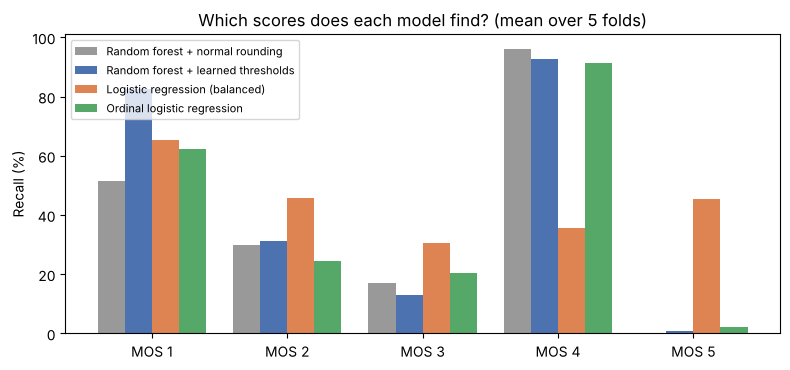

In [10]:
show_models = ["Random forest + normal rounding", "Random forest + learned thresholds",
               "Logistic regression (balanced)", "Ordinal logistic regression"]
colors = ["#999999", "#4C72B0", "#DD8452", "#55A868"]
width = 0.2

fig, ax = plt.subplots(figsize=(8, 3.8))
for i, (name, color) in enumerate(zip(show_models, colors)):
    ax.bar(np.arange(5) + (i - 1.5) * width, recall_table.loc[name] * 100, width, label=name, color=color)
ax.set_xticks(range(5), [f"MOS {s}" for s in SCORES])
ax.set_ylabel("Recall (%)")
ax.set_title("Which scores does each model find? (mean over 5 folds)")
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.savefig("fig_04_recall_per_score.png", dpi=150)
plt.show()

## 8. Confusion matrices
Out-of-fold predictions of 4 models. Each row is shown in % of the real score ("of all real 5s, how many were predicted as 5?"). The diagonal = correct predictions.

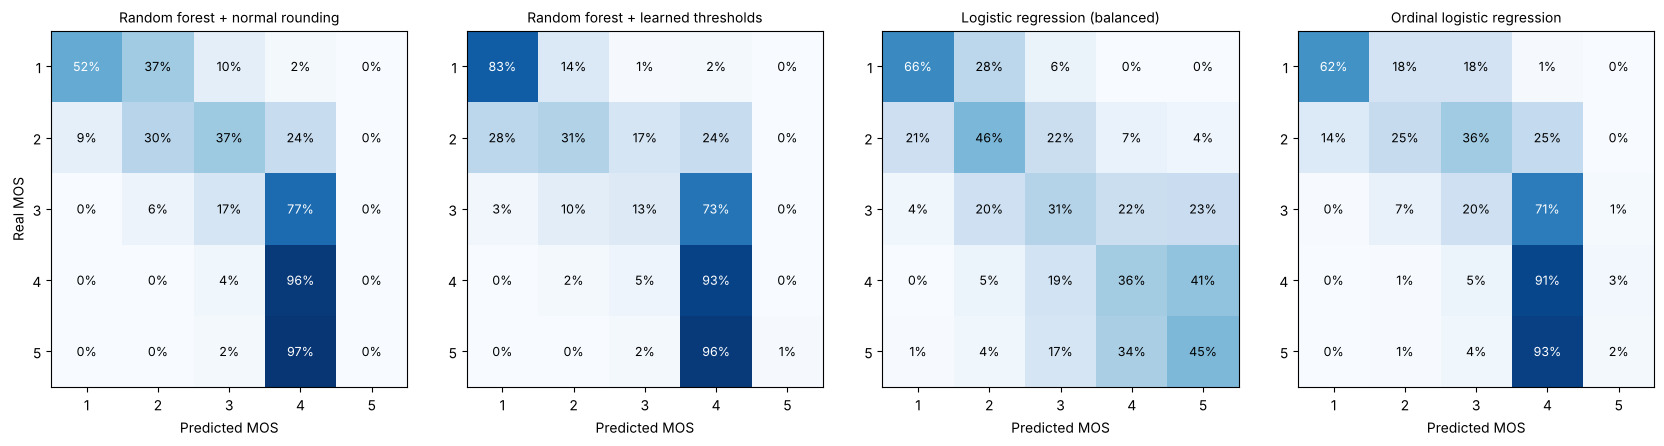

In [11]:
fig, axes = plt.subplots(1, 4, figsize=(17, 4.2))
for ax, name in zip(axes, show_models):
    cm = confusion_matrix(y, oof[name], labels=SCORES)
    pct = cm / cm.sum(axis=1, keepdims=True) * 100
    ax.imshow(pct, cmap="Blues", vmin=0, vmax=100)
    for i in range(5):
        for j in range(5):
            ax.text(j, i, f"{pct[i, j]:.0f}%", ha="center", va="center", fontsize=9,
                    color="white" if pct[i, j] > 50 else "black")
    ax.set_xticks(range(5), SCORES)
    ax.set_yticks(range(5), SCORES)
    ax.set_xlabel("Predicted MOS")
    ax.set_title(name, fontsize=10)
axes[0].set_ylabel("Real MOS")
plt.tight_layout()
plt.savefig("fig_04_confusion_matrices.png", dpi=150)
plt.show()

## 9. Where are the learned cut points?
If the learned cut points are **similar in the 5 folds**, the method is stable. Compare them with normal rounding (1.5, 2.5, 3.5, 4.5).

In [12]:
cuts_table = pd.DataFrame(learned_cuts)
cuts_table.groupby("Model").agg(["mean", "std"]).drop(columns="Fold").round(2)

cut 1|2       cut 2|3       cut 3|4       cut 4|5      
                 mean   std    mean   std    mean   std    mean   std
Model                                                                
Random forest    2.24  0.12    2.86  0.11    3.59  0.16    4.31  0.17
Ridge            2.45  0.04    3.08  0.13    3.41  0.04    4.29  0.03

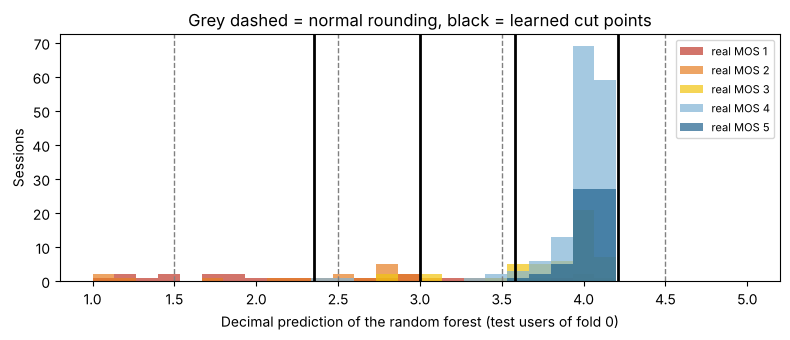

In [13]:
# Picture: decimal predictions of the random forest (out-of-fold) with both sets of cut points
rf_model = threshold_models["Random forest"]
for fold, (tr, te) in enumerate(outer_cv.split(X, y, groups)):
    if fold == 0:   # one fold is enough for the picture
        m = clone(rf_model).fit(X.iloc[tr], y[tr], groups=groups[tr])
        dec, y_te = m.predict_decimal(X.iloc[te]), y[te]
        break

fig, ax = plt.subplots(figsize=(8, 3.5))
for s, color in zip(SCORES, ["#c0392b", "#e67e22", "#f1c40f", "#7fb3d5", "#1f618d"]):
    ax.hist(dec[y_te == s], bins=30, range=(1, 5), alpha=0.7, label=f"real MOS {s}", color=color)
for c in [1.5, 2.5, 3.5, 4.5]:
    ax.axvline(c, color="grey", linestyle="--", lw=1)
for c in m.thresholds_:
    ax.axvline(c, color="black", lw=2)
ax.set_xlabel("Decimal prediction of the random forest (test users of fold 0)")
ax.set_ylabel("Sessions")
ax.set_title("Grey dashed = normal rounding, black = learned cut points")
ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig("fig_04_thresholds.png", dpi=150)
plt.show()

## 10. Why is a 5 so hard to predict?

Even with learned cut points, the random forest predicts almost no 5s: the best cut point between 4 and 5 stays at about 4.3, the top of its predictions.
Moving it lower would turn many real 4s into 5s, and the QWK would go **down**. So the problem is not the rounding.

**Test:** can the model at least **rank** a real 5 above a real 4? We use the **AUC** on the decimal out-of-fold predictions, for each pair of neighbour scores.
- AUC = 1: every session with the higher score gets a higher prediction (perfect ranking).
- AUC = 0.5: no better than flipping a coin.

In [14]:
auc_rows = []
for low, high in [(1, 2), (2, 3), (3, 4), (4, 5)]:
    keep = (y == low) | (y == high)
    auc_rows.append({"Pair": f"{low} vs {high}", "Sessions": int(keep.sum()),
                     **{f"AUC {name}": roc_auc_score(y[keep] == high, decimal_oof[name][keep])
                        for name in threshold_models}})
auc_table = pd.DataFrame(auc_rows)
auc_table.round(2)

,Pair,Sessions,AUC Ridge,AUC Random forest
0,1 vs 2,211,0.81,0.84
1,2 vs 3,363,0.79,0.81
2,3 vs 4,1028,0.71,0.71
3,4 vs 5,1085,0.56,0.54


In [15]:
# Technical quality of the video for each real score (median of each group)
df.groupby(TARGET)[["log_BUFFERINGtime", "QoA_VLCframerate", "QoA_BUFFERINGcount", "QoA_VLCdropped"]].median().round(2)

,log_BUFFERINGtime,QoA_VLCframerate,QoA_BUFFERINGcount,QoA_VLCdropped
MOS,,,,
1,10.27,2.88,2.0,1.0
2,8.97,24.91,1.0,1.0
3,7.92,25.25,1.0,0.0
4,7.87,25.47,1.0,0.0
5,7.78,25.58,1.0,0.0


**What to look for:**
- The model separates **bad** sessions well (1 vs 2, 2 vs 3): a long buffering or a very low frame rate clearly gives a low MOS.
- Between **4 and 5**, the AUC is close to 0.5: the sessions rated 4 and 5 have almost the **same** technical quality.
- So once the video plays well, choosing between "good" and "excellent" depends on the **person** (taste, expectations, mood), not on the measured QoA/QoS/QoD values.
  This fits notebook 03: user profile columns (age, sex, study) bring almost nothing, and we test on **new** users, so the model cannot learn each person's habits.
- → This is a **limit of the data**, not of the model. No model can find 5s reliably with these columns; it can only choose **how many** 5s to guess (the class weights in idea B guess many, the regression models guess almost none).

## 11. Settings chosen in each outer fold

In [16]:
pd.set_option("display.max_colwidth", None)
chosen_table = pd.DataFrame(chosen)
chosen_table["Best settings"] = chosen_table["Best settings"].apply(
    lambda d: {k.replace("model__", ""): v for k, v in d.items()})
chosen_table.pivot(index="Fold", columns="Model", values="Best settings").T

Fold,0,1,2,3,4
Model,,,,,
Baseline (always 4),{},{},{},{},{}
Logistic regression (balanced),{'C': 1},{'C': 0.1},{'C': 0.1},{'C': 1},{'C': 0.1}
Logistic regression (no weights),{'C': 1},{'C': 1},{'C': 1},{'C': 1},{'C': 1}
Ordinal logistic regression,{'alpha': 10},{'alpha': 10},{'alpha': 0.1},{'alpha': 0.01},{'alpha': 0.01}
Random forest,"{'max_depth': 6, 'min_samples_leaf': 1}","{'max_depth': 6, 'min_samples_leaf': 1}","{'max_depth': 6, 'min_samples_leaf': 1}","{'max_depth': 6, 'min_samples_leaf': 1}","{'max_depth': 6, 'min_samples_leaf': 1}"
Random forest classifier (balanced),"{'max_depth': None, 'min_samples_leaf': 20}","{'max_depth': 10, 'min_samples_leaf': 20}","{'max_depth': 10, 'min_samples_leaf': 1}","{'max_depth': 10, 'min_samples_leaf': 1}","{'max_depth': 10, 'min_samples_leaf': 1}"
Ridge,{'alpha': 0.01},{'alpha': 0.01},{'alpha': 0.01},{'alpha': 0.01},{'alpha': 0.01}


## 12. Save the results
File names start with `04_` so they do not replace the files of notebooks 02 and 03.

In [17]:
table.to_csv("results_04_models.csv")
per_fold.to_csv("results_04_models_per_fold.csv", index=False)
recall_table.to_csv("results_04_recall_per_score.csv")
cuts_table.to_csv("results_04_learned_thresholds.csv", index=False)
auc_table.to_csv("results_04_auc_neighbour_scores.csv", index=False)
chosen_table.to_csv("results_04_best_settings.csv", index=False)
print("Saved: 6 results tables (.csv) and 3 figures (.png)")

Saved: 6 results tables (.csv) and 3 figures (.png)
